# Analyse des données

L'objectif de cette étude est d'examiner les relations entre les caractéristiques nutritionnelles des aliments et leurs impacts environnementaux, afin de mieux comprendre les conséquences de nos choix alimentaires. Elle cherche notamment à déterminer dans quelle mesure il est possible de concilier qualité nutritionnelle et réduction de l'impact environnemental de notre alimentation.

Une attention particulière sera portée aux alternatives végétales, afin d'évaluer si elles présentent un réel avantage par rapport aux produits carnés, tant sur le plan environnemental que nutritionnel.

Pour répondre à ces questions, l'analyse s'organise autour de trois axes complémentaires :

**- L'impact environnemental de notre alimentation**  
Cette partie vise à dresser un état des lieux des impacts environnementaux des différents groupes alimentaires, à identifier les principales sources de ces impacts et à étudier les différences entre les catégories de produits.

**- Les alternatives végétales : quels avantages face aux produits carnés ?**  
La deuxième partie se concentre sur la comparaison entre les produits carnés et les alternatives végétales, en étudiant leurs caractéristiques nutritionnelles et leurs impacts environnementaux respectifs.

**- Santé et environnement : existe-t-il un double gain ?**  
Enfin, la dernière partie cherche à identifier les aliments qui présentent à la fois un profil nutritionnel intéressant et un impact environnemental limité, afin d'explorer les possibilités de concilier ces deux objectifs.

Nous utilisons comme base de données finale pour l’analyse la base fusionnée database.csv. Cette base regroupe des informations sur les produits alimentaires, leur composition nutritionnelle et leurs impacts environnementaux. Elle contient 34 variables, qu'on peut regrouper en catégories :

**- Identification et classification des produits :** code_agb (code d’identification d’Agribalyse), code_ciqual (code d’identification de Ciqual), groupe_aliment, sous_groupe_aliment, nom_produit, nom_lci (nom du produit en anglais), preparation (informations relatives à la préparation ou à la conservation du produit) et dqr (note de qualité des données).

**- Impacts environnementaux :** score_unique_ef, changement_climatique, utilisation_du_sol, epuisement_ressources_eau, particules_fines, toxicite_humaine_non_cancerogenes et toxicite_humaine_cancerogenes. Ces indicateurs sont exprimés pour 1 kg de produit alimentaire. Par exemple, le score_unique_ef est un indicateur synthétique regroupant plusieurs impacts environnementaux. Le changement_climatique, exprimé en kg CO₂ eq, mesure la contribution du produit au changement climatique. Enfin, par exemple, l’epuisement_ressources_eau, exprimé en m³ Eau eq, prend en compte la consommation d’eau.

**- Répartition de l’impact climatique selon les étapes du cycle de vie :** changement_climatique_agriculture, changement_climatique_transformation, changement_climatique_emballage, changement_climatique_transport, changement_climatique_distribution et changement_climatique_consommation. Ces variables permettent d’identifier la contribution des différentes étapes du cycle de vie à l’impact climatique d'un produit.

**- Composition nutritionnelle :** la base renseigne l’énergie, les protéines, les glucides, les lipides, les sucres, les fibres alimentaires, le sel, le calcium, le fer, le sodium et la vitamine C.

**- Scores alimentaires :** SAIN et LIM. Ils sont définis dans Exploration_nettoyage_Ciqual.ipynb.

In [6]:
# Chargement de la base de données fusionnée
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import re

database = pd.read_csv("data/database.csv")

print("Dimensions de la base :", database.shape)
database.head(5)

Dimensions de la base : (2296, 34)


,code_agb,code_ciqual,groupe_aliment,sous_groupe_aliment,nom_produit,nom_lci,preparation,dqr,score_unique_ef,changement_climatique,...,Lipides (g 100 g),Sucres (g 100 g),Fibres alimentaires (g 100 g),Sel chlorure de sodium (g 100 g),Calcium (mg 100 g),Fer (mg 100 g),Sodium (mg 100 g),Vitamine C (mg 100 g),SAIN,LIM
0,11172,11172,aides culinaires et ingrédients divers,aides culinaires,"Court-bouillon pour poissons, déshydraté","Aromatic stock cube, for fish, dehydrated",Pas de préparation,2.24,1.870,7.58,...,23.00,4.50,2.50,47.500,0.0,0.00,19000.0,0.0,1.370826,100.000000
1,25525,25525,aides culinaires et ingrédients divers,aides culinaires,"Pizza, sauce garniture pour",Topping sauce for pizza,Pas de préparation,2.19,0.148,0.94,...,0.75,4.57,2.81,0.960,50.0,0.90,385.0,7.0,16.109676,7.258677
2,11214,11214,aides culinaires et ingrédients divers,aides culinaires,"Préparation culinaire à base de soja, type ""cr...","Soy ""cream"" preparation",Pas de préparation,1.75,0.148,1.17,...,14.70,1.60,0.00,0.063,16.0,0.47,25.0,0.0,1.404142,3.830630
3,11084,11084,aides culinaires et ingrédients divers,algues,"Agar (algue), cru","Seaweed, agar, raw",Pas de préparation,2.77,1.550,11.80,...,0.03,0.28,0.50,0.023,54.0,1.86,9.0,0.0,16.397663,0.290785
4,20995,20995,aides culinaires et ingrédients divers,algues,"Ao-nori (Enteromorpha sp.), séchée ou déshydratée","Sea lettuce (Enteromorpha sp.), dried or dehyd...",Pas de préparation,2.77,1.550,11.80,...,2.50,1.35,35.10,10.200,1550.0,205.00,4090.0,48.8,100.000000,44.917791


La base de données finale comporte **2 296 produits alimentaires et 34 variables**. Chaque produit est caractérisé par des informations nutritionnelles (protéines, glucides, lipides, fibres, vitamines, etc.) ainsi que par plusieurs indicateurs environnementaux (changement climatique, utilisation des sols, consommation d'eau, toxicité humaine, etc.).

Cette base permet ainsi de comparer les produits alimentaires selon leurs caractéristiques nutritionnelles et leurs impacts environnementaux.  

Avant de réaliser une analyse approfondie des produits alimentaires, nous avons étudié les corrélations entre les principales variables nutritionnelles et environnementales de notre base de données. Cette matrice permet d'identifier les éventuelles relations entre ces différents indicateurs.

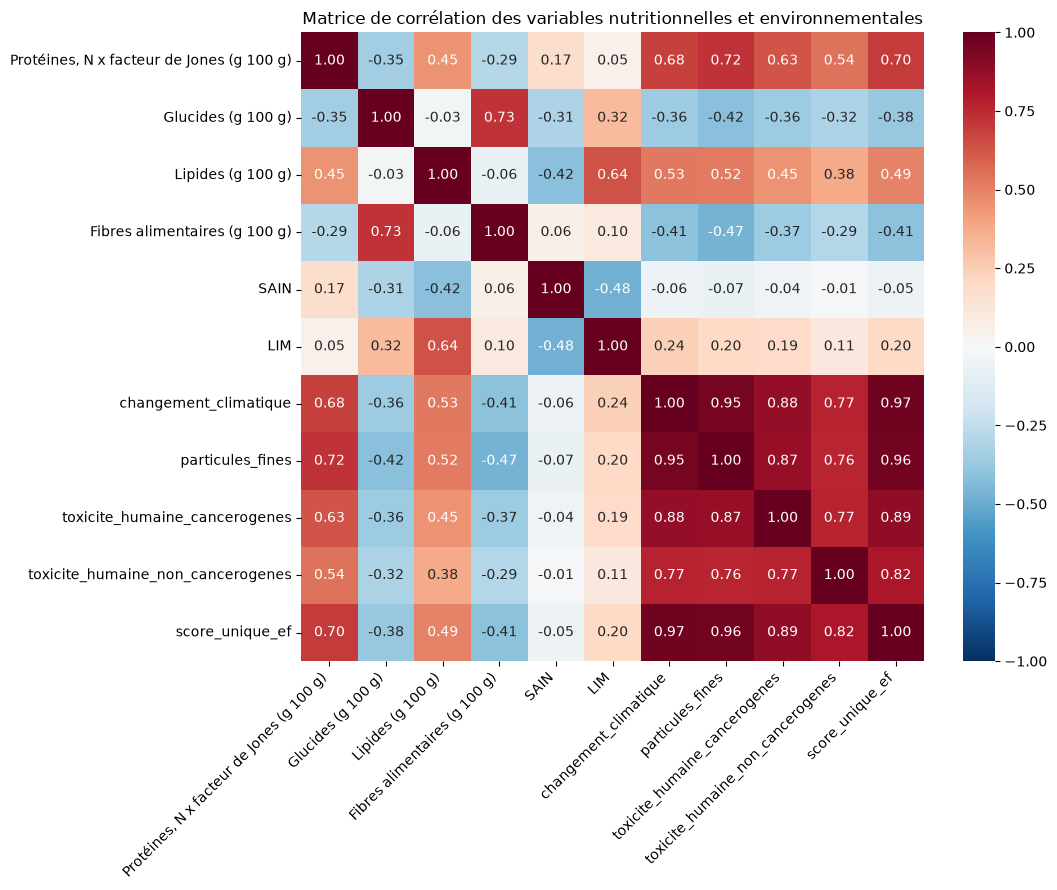

In [23]:
variables = [
    "Protéines, N x facteur de Jones (g 100 g)",
    "Glucides (g 100 g)",
    "Lipides (g 100 g)",
    "Fibres alimentaires (g 100 g)",
    "SAIN", 
    "LIM",
    "changement_climatique",
    "particules_fines",
    "toxicite_humaine_cancerogenes",
    "toxicite_humaine_non_cancerogenes",
    "score_unique_ef"
]

# Matrice de corrélation
corr = database[variables].corr(method="spearman")

# Graphique
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, fmt=".2f")

plt.title("Matrice de corrélation des variables nutritionnelles et environnementales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Cette matrice de corrélation souligne l'intérêt de notre étude en mettant en évidence des relations entre les caractéristiques nutritionnelles et les impacts environnementaux des aliments. On observe notamment de fortes corrélations positives entre les indicateurs environnementaux : le changement climatique est corrélé aux particules fines (0,95) et au score EF (0,97), mais également aux effets toxiques cancérogènes et non cancérogènes. Il présente aussi une corrélation positive avec la teneur en protéines (0,68), ce qui suggère que les aliments les plus riches en protéines tendent également à présenter des impacts environnementaux plus élevés dans notre base. Ces premières observations justifient ainsi l'étude approfondie des liens entre alimentation, nutrition et environnement.

# 1. Impact environnemental de l'alimentation  
Dans cette première partie, nous analysons les impacts environnementaux des différents groupes alimentaires. 

## 1.1. Comparaison des impacts environnementaux des grands groupes alimentaires

In [24]:
# Nombre de groupes et de sous-groupes alimentaires
print("Nombre de groupes alimentaires :", database["groupe_aliment"].nunique())
print("Nombre de sous-groupes alimentaires :", database["sous_groupe_aliment"].nunique())

# Nombre de sous-groupes et de produits par groupe alimentaire
composition_groupes = database.groupby("groupe_aliment").agg(
    nombre_sous_groupes=("sous_groupe_aliment", "nunique"),
    nombre_produits=("nom_produit", "count")
)

# Affichage du tableau
display(composition_groupes.sort_values("nombre_produits", ascending=False))

Nombre de groupes alimentaires : 11
Nombre de sous-groupes alimentaires : 60


,nombre_sous_groupes,nombre_produits
groupe_aliment,,
"viandes, œufs, poissons",12,637
"fruits, légumes, légumineuses et oléagineux",5,391
produits céréaliers,5,333
entrées et plats composés,7,300
lait et produits laitiers,4,196
aides culinaires et ingrédients divers,9,156
boissons,3,134
produits sucrés,4,48
aliments infantiles,4,38


La base de données distingue 11 groupes alimentaires : viandes, œufs, poissons ; fruits, légumes, légumineuses et oléagineux ; produits céréaliers ; entrées et plats composés ; lait et produits laitiers ; aides culinaires et ingrédients divers ; boissons ; produits sucrés ; aliments infantiles ; matières grasses ; glaces et sorbets. Le groupe « viandes, œufs, poissons » est le plus représenté, avec 12 sous-groupes et 637 produits.

In [25]:
# Comparaison des impacts environnementaux des grands groupes d’aliments

# Liste des indicateurs environnementaux disponibles dans la base fusionnée
indicateurs = [
    "score_unique_ef",
    "changement_climatique",
    "utilisation_du_sol",
    "epuisement_ressources_eau",
    "particules_fines",
    "toxicite_humaine_non_cancerogenes",
    "toxicite_humaine_cancerogenes"
]

# Calcul des statistiques environnementales par groupe alimentaire
stats_groupes = database.groupby("groupe_aliment").agg(
    nombre_produits=("nom_produit", "count"),
    **{
        indicateur + "_moyenne": (indicateur, "mean")
        for indicateur in indicateurs
    },
    **{
        indicateur + "_mediane": (indicateur, "median")
        for indicateur in indicateurs
    }
)

# Affichage des résultats
display(stats_groupes)

,nombre_produits,score_unique_ef_moyenne,changement_climatique_moyenne,utilisation_du_sol_moyenne,epuisement_ressources_eau_moyenne,particules_fines_moyenne,toxicite_humaine_non_cancerogenes_moyenne,toxicite_humaine_cancerogenes_moyenne,score_unique_ef_mediane,changement_climatique_mediane,utilisation_du_sol_mediane,epuisement_ressources_eau_mediane,particules_fines_mediane,toxicite_humaine_non_cancerogenes_mediane,toxicite_humaine_cancerogenes_mediane
groupe_aliment,,,,,,,,,,,,,,,
aides culinaires et ingrédients divers,156,0.491599,3.806494,170.781154,4.013111,3.115596e-07,6.355372e-08,2.152250e-09,0.2990,2.3650,83.85,2.4750,1.760000e-07,4.465000e-08,1.215000e-09
aliments infantiles,38,0.200318,1.749921,74.329211,1.052105,1.437737e-07,2.420789e-08,1.844553e-09,0.1440,1.2100,50.50,0.9420,7.325000e-08,1.895000e-08,6.510000e-10
boissons,134,0.143213,1.237856,45.530680,1.350146,7.808706e-08,3.619228e-08,1.080540e-09,0.1170,0.8345,19.05,0.3670,5.550000e-08,1.185000e-08,4.705000e-10
entrées et plats composés,300,0.595310,4.770027,236.383667,3.492481,4.998105e-07,7.362200e-08,2.925997e-09,0.4230,3.2700,136.00,1.1700,2.790000e-07,4.815000e-08,2.225000e-09
"fruits, légumes, légumineuses et oléagineux",391,0.219991,1.478141,135.115217,3.671992,1.063481e-07,4.673046e-08,1.869307e-09,0.1360,1.0400,33.20,0.6820,6.050000e-08,2.300000e-08,8.380000e-10
glaces et sorbets,25,0.259720,2.094400,74.880000,1.196920,1.545760e-07,2.548400e-08,1.061880e-09,0.2380,1.9800,67.70,0.6660,1.600000e-07,2.500000e-08,1.060000e-09
lait et produits laitiers,196,0.476781,4.472602,230.414796,1.024429,4.404061e-07,5.433265e-08,2.231036e-09,0.5005,5.1900,239.00,0.6920,4.270000e-07,6.090000e-08,2.450000e-09
matières grasses,38,0.572816,4.957105,345.928947,7.515579,3.867368e-07,9.436316e-08,4.504658e-09,0.4435,3.6250,339.50,0.8625,2.905000e-07,6.370000e-08,3.320000e-09
produits céréaliers,333,0.298500,2.617913,143.727027,2.533186,1.776829e-07,7.203012e-08,1.656595e-09,0.2840,2.2400,134.00,1.0100,1.700000e-07,3.000000e-08,1.550000e-09


In [26]:
# Recherche des groupes ayant les impacts les plus élevés

for indicateur in indicateurs:
    print(indicateur)
    print("Moyenne maximale :", stats_groupes[indicateur + "_moyenne"].idxmax())
    print("Médiane maximale :", stats_groupes[indicateur + "_mediane"].idxmax())

score_unique_ef
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
changement_climatique
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
utilisation_du_sol
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : matières grasses
epuisement_ressources_eau
Moyenne maximale : matières grasses
Médiane maximale : aides culinaires et ingrédients divers
particules_fines
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
toxicite_humaine_non_cancerogenes
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
toxicite_humaine_cancerogenes
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons


Le groupe viandes, œufs et poissons présente la moyenne et la médiane les plus élevées pour 5 indicateurs sur 7. Il possède notamment le score unique EF moyen le plus élevé (1,64) et l’impact climatique moyen le plus élevé (13,18 kg CO₂ eq/kg), ainsi que les médianes les plus élevées pour ces deux indicateurs (1,27 et 7,75 kg CO₂ eq/kg). Les résultats diffèrent pour l'utilisation des sols : les viandes, œufs et poissons ont la moyenne la plus élevée, mais les matières grasses ont la médiane la plus élevée. L'épuisement des ressources en eau présente un résultat différent : les matières grasses ont la moyenne la plus élevée, tandis que les aides culinaires et ingrédients divers ont la médiane la plus élevée.

In [27]:
# Recherche des groupes ayant les impacts les plus faibles

for indicateur in indicateurs:
    print(indicateur)
    print("Moyenne minimale :", stats_groupes[indicateur + "_moyenne"].idxmin())
    print("Médiane minimale :", stats_groupes[indicateur + "_mediane"].idxmin())

score_unique_ef
Moyenne minimale : boissons
Médiane minimale : boissons
changement_climatique
Moyenne minimale : boissons
Médiane minimale : boissons
utilisation_du_sol
Moyenne minimale : boissons
Médiane minimale : boissons
epuisement_ressources_eau
Moyenne minimale : lait et produits laitiers
Médiane minimale : boissons
particules_fines
Moyenne minimale : boissons
Médiane minimale : boissons
toxicite_humaine_non_cancerogenes
Moyenne minimale : aliments infantiles
Médiane minimale : boissons
toxicite_humaine_cancerogenes
Moyenne minimale : glaces et sorbets
Médiane minimale : boissons


Les boissons ont globalement les impacts environnementaux les plus faibles parmi les 11 groupes alimentaires, avec notamment un score unique EF médian de 0,117 et un impact climatique médian de 0,83 kg CO₂ eq/kg.

Le graphique ci-dessous présente la médiane de l’indicateur « changement climatique » pour chaque groupe alimentaire.

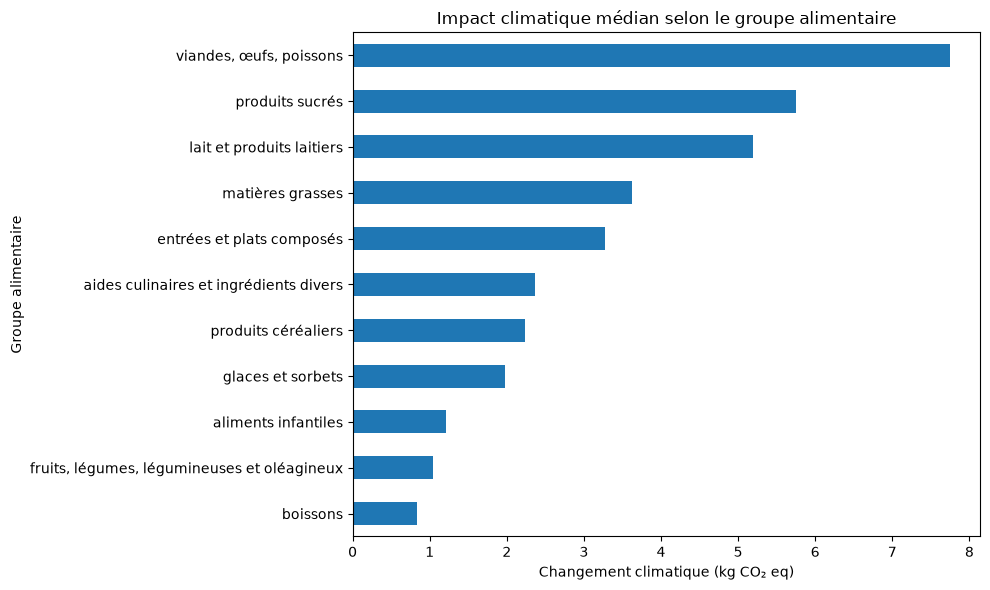

In [28]:
# Graphique sur l'impact climatique médian des groupes alimentaires

impact_climatique_groupes = (
    database.groupby("groupe_aliment")["changement_climatique"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 6))

impact_climatique_groupes.plot(kind="barh")

plt.xlabel("Changement climatique (kg CO₂ eq)")
plt.ylabel("Groupe alimentaire")
plt.title("Impact climatique médian selon le groupe alimentaire")

plt.tight_layout()
plt.show()

Ce graphique montre que le groupe « viandes, œufs, poissons » présente l'impact climatique médian le plus élevé parmi les groupes alimentaires étudiés. 

Après avoir identifié les groupes alimentaires présentant les impacts environnementaux les plus élevés, notamment en matière de changement climatique, il convient maintenant de déterminer quelles étapes du cycle de vie des produits contribuent le plus à leur impact climatique (agriculture, transformation, emballage, transport, distribution et consommation).

## 1.2. Identification des principaux postes responsables de l’impact climatique

In [29]:
# Identification des principaux postes du cycle de vie responsables de l’impact climatique

postes_climatiques = [
    "changement_climatique_agriculture",
    "changement_climatique_transformation",
    "changement_climatique_emballage",
    "changement_climatique_transport",
    "changement_climatique_distribution",
    "changement_climatique_consommation"
]

# Calcul de la moyenne et de la médiane pour chaque poste
stats_postes = database[postes_climatiques].agg(["mean", "median"]).T

# Renommage des colonnes
stats_postes.columns = ["moyenne", "mediane"]

# Classement des postes selon leur impact moyen 
stats_postes = stats_postes.sort_values(
    "moyenne", ascending=False
)

# Affichage du tableau final
display(stats_postes)

,moyenne,mediane
changement_climatique_agriculture,4.731860,1.65000
changement_climatique_emballage,0.456006,0.40100
changement_climatique_transport,0.388006,0.28350
changement_climatique_transformation,0.250495,0.17050
changement_climatique_consommation,0.045827,0.00683
changement_climatique_distribution,0.036326,0.03680


Les résultats montrent que l'agriculture constitue le principal contributeur à l'impact climatique des produits alimentaires étudiés, avec un impact moyen d'environ 4,73 kg CO₂ eq par kg de produit. 

In [30]:
# Identification des principaux postes du cycle de vie responsables de l’impact climatique par groupe alimentaire

# Calcul de la moyenne pour chaque poste et chaque groupe
moyennes_postes_groupes = database.groupby("groupe_aliment")[postes_climatiques].mean()

# Affichage des résultats
display(moyennes_postes_groupes)

,changement_climatique_agriculture,changement_climatique_transformation,changement_climatique_emballage,changement_climatique_transport,changement_climatique_distribution,changement_climatique_consommation
groupe_aliment,,,,,,
aides culinaires et ingrédients divers,2.012561,0.343787,1.103194,0.300615,0.031270,0.011589
aliments infantiles,0.987147,0.095940,0.454197,0.182008,0.024597,0.006042
boissons,0.461191,0.136341,0.366494,0.243546,0.024331,0.005533
entrées et plats composés,3.562642,0.310883,0.473632,0.342409,0.035313,0.043431
"fruits, légumes, légumineuses et oléagineux",0.648670,0.105881,0.235987,0.363803,0.040182,0.083496
glaces et sorbets,1.071720,0.186240,0.494000,0.251440,0.066508,0.025800
lait et produits laitiers,3.519811,0.226175,0.393815,0.261138,0.035465,0.006133
matières grasses,3.690895,0.191863,0.664895,0.379184,0.027216,0.002876
produits céréaliers,1.771982,0.188643,0.412771,0.209450,0.023600,0.010852


L'agriculture est le principal poste contributeur dans les 11 groupes alimentaires. 

Après avoir identifié le groupe « viandes, œufs et poissons » comme présentant les impacts environnementaux les plus élevés, intéressons-nous aux différences entre ses sous-groupes.

## 1.3. Hétérogénéité des impacts au sein du groupe « viandes, œufs et poissons »

In [31]:
# Sélection du groupe viandes, œufs et poissons
animaux = database[
    database["groupe_aliment"] == "viandes, œufs, poissons"
]

# Calcul des statistiques descriptives par sous-groupe
stats_sous_groupes = animaux.groupby("sous_groupe_aliment").agg(
    nombre_produits=("nom_produit", "count"),
    **{
        indicateur + "_moyenne": (indicateur, "mean")
        for indicateur in indicateurs
    },
    **{
        indicateur + "_mediane": (indicateur, "median")
        for indicateur in indicateurs
    }
)

# Affichage du tableau
display(stats_sous_groupes)

,nombre_produits,score_unique_ef_moyenne,changement_climatique_moyenne,utilisation_du_sol_moyenne,epuisement_ressources_eau_moyenne,particules_fines_moyenne,toxicite_humaine_non_cancerogenes_moyenne,toxicite_humaine_cancerogenes_moyenne,score_unique_ef_mediane,changement_climatique_mediane,utilisation_du_sol_mediane,epuisement_ressources_eau_mediane,particules_fines_mediane,toxicite_humaine_non_cancerogenes_mediane,toxicite_humaine_cancerogenes_mediane
sous_groupe_aliment,,,,,,,,,,,,,,,
autres produits à base de viande,13,1.780769,15.031538,1080.000000,3.275385,1.849077e-06,2.334769e-07,8.886923e-09,1.2300,7.41,445.0,3.220,1.370000e-06,1.160000e-07,7.850000e-09
charcuteries,142,1.114141,9.033169,492.412676,2.508718,9.952465e-07,1.116401e-07,6.121479e-09,0.9695,7.42,374.0,2.405,7.965000e-07,8.390000e-08,5.390000e-09
mollusques et crustacés crus,13,1.582769,11.678462,146.263846,28.120615,1.075769e-06,1.309077e-07,8.500000e-09,1.3300,9.89,243.0,0.965,1.290000e-06,7.000000e-08,5.720000e-09
mollusques et crustacés cuits,7,2.830571,18.808571,120.990000,32.099286,2.073000e-06,2.628429e-07,1.747714e-08,1.6200,11.80,89.0,0.847,1.610000e-06,8.640000e-08,6.980000e-09
poissons crus,94,1.427574,8.315426,39.289149,8.733564,1.364191e-06,7.843511e-08,4.679596e-09,1.5700,8.42,16.2,0.470,1.320000e-06,5.650000e-08,4.670000e-09
poissons cuits,55,1.684345,9.753818,76.576364,20.247127,1.524000e-06,8.864909e-08,5.830000e-09,1.5800,9.22,24.2,0.709,1.100000e-06,7.060000e-08,6.080000e-09
produits à base de poissons et produits de la mer,45,0.988022,6.572889,106.074667,3.830689,1.011089e-06,6.824667e-08,6.130000e-09,0.8610,6.11,60.7,0.635,6.830000e-07,5.710000e-08,4.880000e-09
substituts de charcuterie,3,0.274333,2.120000,126.766667,0.556333,1.140667e-07,4.046667e-08,2.370000e-09,0.3020,2.17,134.0,0.577,1.230000e-07,3.590000e-08,2.270000e-09
substituts de viande,8,0.252688,2.013750,110.162500,2.920375,1.149000e-07,3.817125e-08,1.422750e-09,0.2440,2.02,115.0,0.590,1.060000e-07,2.745000e-08,1.410000e-09


In [32]:
# Recherche des sous-groupes ayant les impacts les plus élevés
for indicateur in indicateurs:
    print("\n", indicateur)
    print("Moyenne maximale :", stats_sous_groupes[indicateur + "_moyenne"].idxmax())
    print("Médiane maximale :", stats_sous_groupes[indicateur + "_mediane"].idxmax())


 score_unique_ef
Moyenne maximale : mollusques et crustacés cuits
Médiane maximale : viandes cuites

 changement_climatique
Moyenne maximale : viandes cuites
Médiane maximale : viandes cuites

 utilisation_du_sol
Moyenne maximale : viandes cuites
Médiane maximale : viandes cuites

 epuisement_ressources_eau
Moyenne maximale : mollusques et crustacés cuits
Médiane maximale : viandes cuites

 particules_fines
Moyenne maximale : viandes cuites
Médiane maximale : viandes cuites

 toxicite_humaine_non_cancerogenes
Moyenne maximale : viandes cuites
Médiane maximale : viandes cuites

 toxicite_humaine_cancerogenes
Moyenne maximale : mollusques et crustacés cuits
Médiane maximale : viandes cuites


On constate que les viandes cuites présentent les médianes les plus élevées pour les sept indicateurs environnementaux étudiés.

In [33]:
# Recherche des sous-groupes ayant les impacts les plus faibles
for indicateur in indicateurs:
    print("\n", indicateur)
    print("Moyenne minimale :", stats_sous_groupes[indicateur + "_moyenne"].idxmin())
    print("Médiane minimale :", stats_sous_groupes[indicateur + "_mediane"].idxmin())


 score_unique_ef
Moyenne minimale : substituts de viande
Médiane minimale : substituts de viande

 changement_climatique
Moyenne minimale : substituts de viande
Médiane minimale : substituts de viande

 utilisation_du_sol
Moyenne minimale : poissons crus
Médiane minimale : poissons crus

 epuisement_ressources_eau
Moyenne minimale : substituts de charcuterie
Médiane minimale : poissons crus

 particules_fines
Moyenne minimale : substituts de charcuterie
Médiane minimale : substituts de viande

 toxicite_humaine_non_cancerogenes
Moyenne minimale : substituts de viande
Médiane minimale : substituts de viande

 toxicite_humaine_cancerogenes
Moyenne minimale : substituts de viande
Médiane minimale : substituts de viande


Les substituts de viande présentent globalement les impacts les plus faibles parmi les sous-groupes étudiés.

Si l'on se concentre sur l’impact climatique et le score unique EF global, on constate que les impacts environnementaux sont très hétérogènes au sein du groupe viandes, œufs et poissons. 
Les viandes cuites et crues présentent les impacts climatiques médians les plus élevés, tandis que les œufs et surtout les substituts de viande et de charcuterie présentent des impacts nettement plus faibles. 
Par exemple, la médiane de l'impact climatique des viandes cuites est de 29,70 kg CO₂ eq/kg de produit, contre 2,02 kg CO₂ eq/kg pour les substituts de viande. De plus, les viandes cuites présentent un score unique EF médian de 2,82, contre 0,244 pour les substituts de viande. Ce score est un indicateur synthétique qui regroupe plusieurs impacts environnementaux en un seul indicateur. 
Cependant, ces sous-groupes sont représentés par des effectifs très différents dans la base : les viandes cuites comptent 104 produits et les viandes crues 132, contre 3 produits pour les substituts de charcuterie et 8 pour les substituts de viande. 

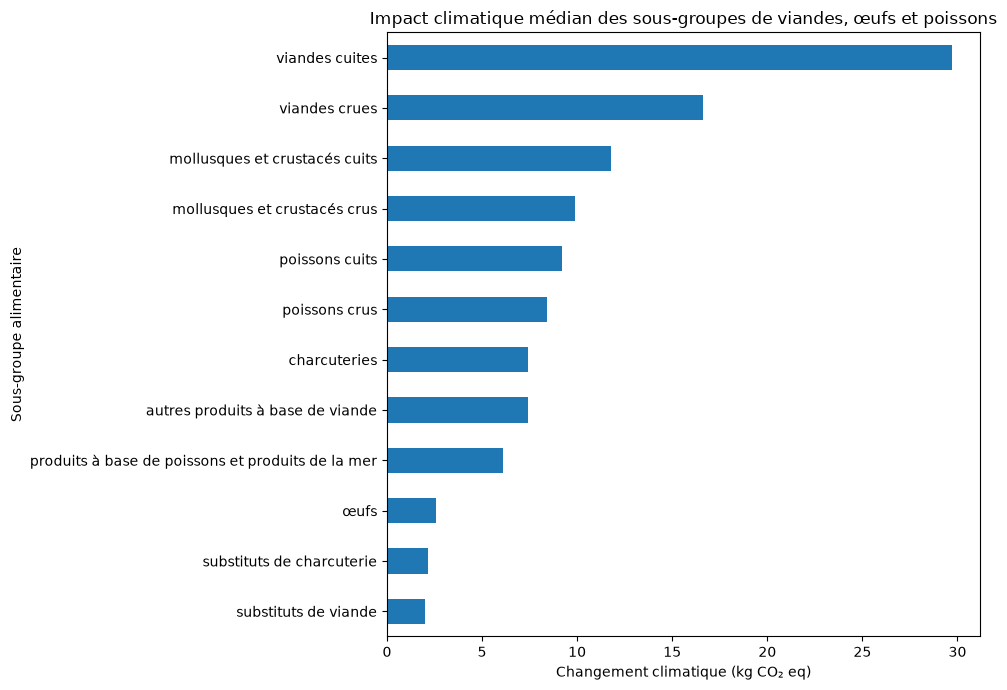

In [34]:
# Graphique sur l'impact climatique médian des sous-groupes
# du groupe "viandes, œufs et poissons"

impact_climatique_sous_groupes = (
    database[
        database["groupe_aliment"] == "viandes, œufs, poissons"
    ]
    .groupby("sous_groupe_aliment")["changement_climatique"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 7))

impact_climatique_sous_groupes.plot(kind="barh")

plt.xlabel("Changement climatique (kg CO₂ eq)")
plt.ylabel("Sous-groupe alimentaire")
plt.title(
    "Impact climatique médian des sous-groupes "
    "de viandes, œufs et poissons"
)

plt.tight_layout()
plt.show()

Le graphique met en évidence de fortes disparités entre les sous-groupes : les viandes cuites présentent l'impact climatique médian le plus élevé, avec près de 30 kg CO₂-éq/kg, devant les viandes crues (environ 17 kg). À l'inverse, les substituts de viande et de charcuterie affichent des impacts nettement plus faibles, près de dix fois inférieurs à celui des viandes cuites. Ces résultats montrent que des alternatives végétales peuvent permettre de réduire considérablement l'empreinte climatique des produits carnés.

# 2. Les alternatives végétales : quels avantages face aux produits carnés ?

L'alimentation végétarienne repose sur l'exclusion de la viande et du poisson. Elle nécessite donc de trouver d'autres sources de protéines et de nutriments habituellement apportés par les produits carnés. Dans cette partie, nous cherchons à étudier les principales alternatives végétales susceptibles de contribuer à ces apports nutritionnels, et à les comparer aux produits carnés.

Nous distinguons ainsi deux grandes familles :
- Les produits carnés, comprenant les viandes, les charcuteries et les poissons.
- Les alternatives végétales, comprenant les légumineuses, les fruits à coque et graines oléagineuses, ainsi que les substituts végétaux de viande et de charcuterie et plats végétariens.


Les alternatives végétales ont été choisi en suivant les conseils de spécialistes de l'alimentation, qui présentent ces produits comme des alternatives aux produits carnés pour subvenir correctement à nos besoins. En effet :
    - Les légumineuses (lentilles, pois chiches, haricots…) sont une source importante de protéines végétales et de fibres.
    - Les fruits à coque et graines oléagineuses (noix, amandes, noisettes, graines…) apportent des lipides, des protéines, des fibres et différents micronutriments. Ils constituent des aliments intéressants pour compléter l'alimentation végétarienne, même s'ils ne remplacent pas directement la viande.
    - Les substituts végétaux (tofu, produits à base de soja, substituts de charcuterie…) sont conçus pour reproduire certaines caractéristiques des produits carnés, notamment leur apport en protéines.
    - Les plats végétariens permettent d'étudier des préparations sans viande ni poisson, mais leur intérêt nutritionnel dépend fortement de leur composition.

## 2.1. Constitution et analyse de la base d'étude

In [35]:

# 1. Création d'une copie temporaire de la base
analyse_vegetale = database.copy()


# 2. Définition des catégories alimentaires

# Produits carnés : viandes, charcuteries et produits de la mer
produits_carnes = [
    "viandes crues",
    "viandes cuites",
    "charcuteries",
    "autres produits à base de viande",
    "poissons crus",
    "poissons cuits",
    "produits à base de poissons et produits de la mer",
    "mollusques et crustacés crus",
    "mollusques et crustacés cuits"
]

# Alternatives végétales : sources de protéines et substituts
alternatives_vegetales = [
    "légumineuses",
    "fruits à coque et graines oléagineuses",
    "substituts de viande",
    "substituts de charcuterie",
    "plats végétariens"
]


# 3. Classement des produits
analyse_vegetale["categorie_analyse"] = None

analyse_vegetale.loc[
    analyse_vegetale["sous_groupe_aliment"].isin(produits_carnes),
    "categorie_analyse"
] = "Produits carnés"

analyse_vegetale.loc[
    analyse_vegetale["sous_groupe_aliment"].isin(alternatives_vegetales),
    "categorie_analyse"
] = "Alternatives végétales"


# 4. Conservation des produits appartenant aux deux catégories
analyse_vegetale = analyse_vegetale.dropna(
    subset=["categorie_analyse"]
).copy()


# 5. Vérification des effectifs par catégorie et sous-catégorie

# Effectifs des deux grandes catégories
effectifs = (
    analyse_vegetale["categorie_analyse"]
    .value_counts()
    .rename("Nombre de produits")
)

display(effectifs.to_frame())


# Effectifs détaillés par sous-catégorie
effectifs_sous_groupes = (
    analyse_vegetale
    .groupby(["categorie_analyse", "sous_groupe_aliment"])
    .size()
    .rename("Nombre de produits")
    .reset_index()
    .sort_values(
        ["categorie_analyse", "Nombre de produits"],
        ascending=[True, False]
    )
)

display(effectifs_sous_groupes)


,Nombre de produits
categorie_analyse,
Produits carnés,605
Alternatives végétales,113


,categorie_analyse,sous_groupe_aliment,Nombre de produits
0,Alternatives végétales,fruits à coque et graines oléagineuses,45
1,Alternatives végétales,légumineuses,33
2,Alternatives végétales,plats végétariens,24
4,Alternatives végétales,substituts de viande,8
3,Alternatives végétales,substituts de charcuterie,3
6,Produits carnés,charcuteries,142
12,Produits carnés,viandes crues,132
13,Produits carnés,viandes cuites,104
9,Produits carnés,poissons crus,94
10,Produits carnés,poissons cuits,55


## 2.2. Comparaison des profils nutritionnels et environnementaux
Cette partie permet de présenter les deux catégories de produits étudiées et de comparer globalement leurs caractéristiques et leurs impacts environnementaux et nutritionnels.

score_unique_ef        changement_climatique         \
                                  mean median                  mean median   
categorie_analyse                                                            
Alternatives végétales           0.346  0.282                 2.260   2.13   
Produits carnés                  1.702  1.300                13.728   7.96   

                       toxicite_humaine_non_cancerogenes         \
                                                    mean median   
categorie_analyse                                                 
Alternatives végétales                               0.0    0.0   
Produits carnés                                      0.0    0.0   

                       toxicite_humaine_cancerogenes         
                                                mean median  
categorie_analyse                                            
Alternatives végétales                           0.0    0.0  
Produits carnés                                  0.0    0.0

Protéines, N x facteur de Jones (g 100 g)         \
                                                            mean median   
categorie_analyse                                                         
Alternatives végétales                                     14.20   14.1   
Produits carnés                                            19.85   19.6   

                       Glucides (g 100 g)        Lipides (g 100 g)         \
                                     mean median              mean median   
categorie_analyse                                                           
Alternatives végétales              17.78   12.3             20.25  10.20   
Produits carnés                      1.57    0.2             11.16   7.85   

                       Fibres alimentaires (g 100 g)        Fer (mg 100 g)  \
                                                mean median           mean   
categorie_analyse                                                            
Alternatives végétales                          8.28    6.7           3.08   
Produits carnés                                 0.16    0.0           1.73   

                              Calcium (mg 100 g)         SAIN           LIM  \
                       median               mean median  mean median   mean   
categorie_analyse                                                             
Alternatives végétales    2.2              94.36   69.0  7.31   6.97  10.26   
Produits carnés           0.9              20.77   11.0  6.54   5.79   8.59   

                               
                       median  
categorie_analyse              
Alternatives végétales   7.97  
Produits carnés          4.73

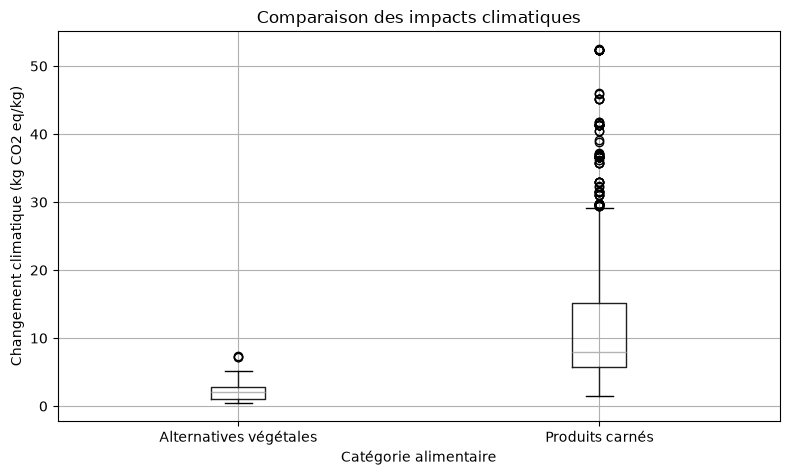

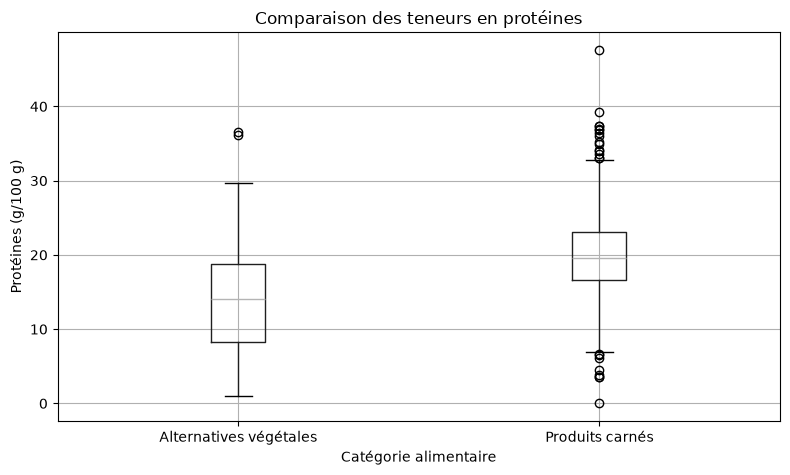

In [36]:
# Comparaison des impacts environnementaux

indicateurs_env = [
    "score_unique_ef",
    "changement_climatique",
    "toxicite_humaine_non_cancerogenes",
    "toxicite_humaine_cancerogenes"
]

comparaison_env = analyse_vegetale.groupby("categorie_analyse")[
    indicateurs_env
].agg(["mean", "median"])

display(comparaison_env.round(3))


# Comparaison des caractéristiques nutritionnelles

indicateurs_nutrition = [
    "Protéines, N x facteur de Jones (g 100 g)",
    "Glucides (g 100 g)",
    "Lipides (g 100 g)",
    "Fibres alimentaires (g 100 g)",
    "Fer (mg 100 g)",
    "Calcium (mg 100 g)",
    "SAIN",
    "LIM"
]

comparaison_nutrition = analyse_vegetale.groupby("categorie_analyse")[
    indicateurs_nutrition
].agg(["mean", "median"])

display(comparaison_nutrition.round(2))


# Comparaison des impacts climatiques

import matplotlib.pyplot as plt

analyse_vegetale.boxplot(
    column="changement_climatique",
    by="categorie_analyse",
    figsize=(8, 5)
)

plt.title("Comparaison des impacts climatiques")
plt.suptitle("")
plt.xlabel("Catégorie alimentaire")
plt.ylabel("Changement climatique (kg CO2 eq/kg)")
plt.tight_layout()
plt.show()


# Comparaison des teneurs en protéines

analyse_vegetale.boxplot(
    column="Protéines, N x facteur de Jones (g 100 g)",
    by="categorie_analyse",
    figsize=(8, 5)
)

plt.title("Comparaison des teneurs en protéines")
plt.suptitle("")
plt.xlabel("Catégorie alimentaire")
plt.ylabel("Protéines (g/100 g)")
plt.tight_layout()
plt.show()

La comparaison met en évidence un avantage environnemental marqué des alternatives végétales : leur score EF moyen est près de cinq fois inférieur à celui des produits carnés (0,346 contre 1,702), tandis que leur impact climatique moyen est également nettement plus faible (2,26 contre 13,73 kg CO₂ éq/kg). Sur le plan nutritionnel, les produits carnés présentent une teneur moyenne en protéines supérieure (19,85 contre 14,20 g/100 g), mais les alternatives végétales restent relativement riches en protéines, comme le montre leur distribution sur le graphique. Elles se distinguent surtout par des teneurs plus élevées en fibres, en fer et en calcium. Cette tendance se retrouve dans le score SAIN, légèrement supérieur pour les alternatives végétales (7,31 contre 6,54 sur 10), même si leur score LIM plus élevé (10,26 contre 8,59) souligne également certaines limites nutritionnelles. Ainsi, les alternatives végétales constituent une option intéressante pour réduire l'impact environnemental tout en conservant un profil nutritionnel satisfaisant, sans pour autant être systématiquement supérieures aux produits carnés sur tous les critères. 

Pour aller plus loin dans l’analyse, nous allons maintenant nous intéresser à la composition nutritionnelle de ces produits. Nous étudierons les différentes teneurs en nutriments afin d’établir un profil nutritionnel moyen pour chaque gamme de produits, représenté sous la forme d’un graphique radar.
Pour comparer les profils nutritionnels des produits étudiés, nous nous appuyons sur les apports de référence journaliers établis pour un adulte. Les valeurs relatives aux macronutriments, au sel, aux vitamines et aux minéraux proviennent du règlement européen (UE) n° 1169/2011, tandis que la référence de 25 g pour les fibres alimentaires s'appuie sur les recommandations de l'EFSA. Ces valeurs constituent des repères de comparaison et ne correspondent pas à des objectifs à atteindre avec un seul aliment.

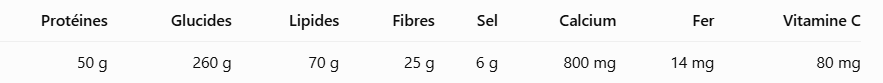

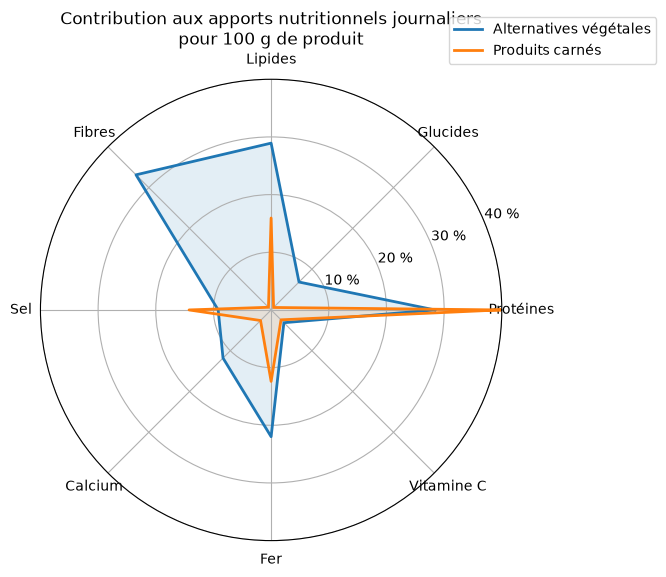

In [37]:
# Références nutritionnelles journalières
references = {
    "Protéines": 50,
    "Glucides": 260,
    "Lipides": 70,
    "Fibres": 25,
    "Sel": 6,
    "Calcium": 800,
    "Fer": 14,
    "Vitamine C": 80
}

# Correspondance avec les colonnes de la base
colonnes = {
    "Protéines": "Protéines, N x facteur de Jones (g 100 g)",
    "Glucides": "Glucides (g 100 g)",
    "Lipides": "Lipides (g 100 g)",
    "Fibres": "Fibres alimentaires (g 100 g)",
    "Sel": "Sel chlorure de sodium (g 100 g)",
    "Calcium": "Calcium (mg 100 g)",
    "Fer": "Fer (mg 100 g)",
    "Vitamine C": "Vitamine C (mg 100 g)"
}

# Calcul des moyennes pour chaque catégorie
moyennes = analyse_vegetale.groupby("categorie_analyse")[
    list(colonnes.values())
].mean()

moyennes.columns = list(colonnes.keys())

# Calcul de la contribution aux apports journaliers (%)
profils = moyennes.copy()

for nutriment, reference in references.items():
    profils[nutriment] = profils[nutriment] / reference * 100

# Construction du diagramme radar
nutriments = list(profils.columns)
N = len(nutriments)

angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"polar": True})

for categorie in profils.index:
    valeurs = profils.loc[categorie].tolist()
    valeurs += valeurs[:1]

    ax.plot(angles, valeurs, linewidth=2, label=categorie)
    ax.fill(angles, valeurs, alpha=0.12)

# Adaptation automatique de l'échelle
maximum = profils.max().max()
limite = max(10, np.ceil(maximum / 10) * 10)

ax.set_ylim(0, limite)
ax.set_yticks(np.arange(0, limite + 1, 10))
ax.set_yticklabels([f"{int(x)} %" for x in np.arange(0, limite + 1, 10)])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(nutriments)

ax.set_title(
    "Contribution aux apports nutritionnels journaliers\npour 100 g de produit",
    pad=25
)

ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15))

plt.tight_layout()
plt.show()


Le graphique met en évidence des profils nutritionnels différenciés selon les catégories de produits. Les produits carnés présentent une contribution plus importante en protéines (environ 40 % des apports journaliers de référence pour 100 g, contre 30 % pour les alternatives végétales). À l’inverse, ces dernières se distinguent par des teneurs plus élevées en fibres, en glucides, en lipides et en plusieurs micronutriments, notamment le fer et le calcium.

Les alternatives végétales apportent également davantage de fibres, tandis que les produits carnés présentent une teneur en sel supérieure (environ 15 % contre 8 %). Or, une consommation excessive de sodium favorise l'hypertension et augmente les risques cardiovasculaires, selon l'OMS.

## 3. Santé et environnement : existe-t-il un double gain ?

Dans cette dernière partie, nous essayons de croiser la performance nutritionnelle (scores SAIN et LIM) et l'impact environnemental afin de répondre à trois questions :
1. Existe-t-il un arbitrage systématique entre qualité nutritionnelle et faible impact écologique ?
2. Comment se positionnent les *produits animaux*, les produits adapté à un *régime végétarien* et les *alternatives végétales pures* dans cet espace ?
3. Quels aliments atteignent réellement un *double gain* (frontière d'efficacité) ?

In [ ]:
# Définition du ratio SAIN/LIM
df1 = pd.read_csv("data/database.csv")

# Définition des groupes d'analyse

## NB: ici la catégorisation des produits (animal, vege_non_vegan, vegan) s'appuie d'abord sur groupe_aliment et sous_groupe_aliment, toutefois n'utiliser que ces catégories déja présentes dans la base laisserait de côté certains aliments,
# pour palier ce problème, on poursuit cette catégorisation manuellement par repérage de mots-clés dans nom_produit afin de traiter les exceptions (des faux amis comme certaines préparations à base de lait de coco, 
# ou encore des espèces particulières d'haricots ...). Cette approche nous permet de trier l'ensemble de la base plus finement, mais des faux positifs/faux négatifs peuvent encore subsister (même si normalement le tri a bien été opéré)

def classificateur(row):
  groupe = str(row["groupe_aliment"]).lower()
  sous_grp = str(row["sous_groupe_aliment"]).lower()
  nom = str(row["nom_produit"]).lower()

  # Exceptions 100 % végétales (pour parer à certains faux amis linguistiques à partir de lait de coco)
  exceptions_veganes = [
      "soja","tofu","seitan",
      "végétale","végétal",
      "convient aux véganes",
      "lait de coco","crème de coco",
      "beurre de cacahuète","haricot beurre",
      "melon miel"]

  if any(mot in nom for mot in exceptions_veganes) and "poulet" not in nom:
    if "ne convient pas aux véganes" in nom or "fromage" in nom:
      return "vege_non_vegan"
    return "vegan"

  # Produits animaux (viandes, poissons, fruits de mer, charcuteries, plats carnés)
  if groupe == "viandes, œufs, poissons" and sous_grp != "œufs":
    return "animal"
  if sous_grp in ["autres matières grasses", "huiles de poissons"]:
    return "animal"

  mots_animaux = (
      r"\b(viande|boeuf|bœuf|veau|porc|jambon|lardons?|poulet|volaille|dinde|canard|"
      r"agneau|mouton|lapin|tripes|escargots?|saucisses?|saucissons?|merguez|chorizo|"
      r"salami|speck|pâté|bolognaise|carbonara|lorraine|kebab|hot-dog|hamburger|"
      r"cheeseburger|croque-monsieur|croque-madame|cassoulet|chili con carne|"
      r"choucroute garnie|pot-au-feu|osso buco|coq au vin|moussaka|paëlla|tajine|"
      r"poissons?|saumon|thon|anchois|crevettes?|crabe|moules?|st jacques|"
      r"saint-jacques|fruits de mer|produits de la mer|sushi|maki|gélatine)\b"
  )
  if (re.search(mots_animaux, nom)
      and "sans viande" not in nom
      and "végétal" not in nom):
    return "animal"

  # 2. Produits végétariens non végans (œufs, lait, fromage, beurre, pâtisseries)
  if groupe == "lait et produits laitiers" or sous_grp in [
      "œufs","beurres","glaces",
      "desserts glacés","gâteaux et pâtisseries"]:
    return "vege_non_vegan"

  mots_vege_non_vegan = (
      r"\b(fromages?|roquefort|maroilles|chèvre|tomme|raclette|tartiflette|savoyarde|"
      r"aligot|béchamel|crème|beurre|lait|lactée?s?|yaourt|oeufs?|œufs?|miel|"
      r"mayonnaise|hollandaise|béarnaise|tartare|rouille|brioche|croissant|quiche|"
      r"gratin|lasagnes|canelloni|raviolis?|ravioles|risotto|pizza aux légumes)\b"
  )
  if re.search(mots_vege_non_vegan, nom):
    return "vege_non_vegan"

  # 3. Produits végans
  return "vegan"


df1["type_base"] = df1.apply(classificateur, axis=1)
df1["est_animal"] = df1["type_base"] == "animal"
df1["est_vegetarien"] = df1["type_base"].isin(["vege_non_vegan", "vegan"])
df1["est_vegan"] = df1["type_base"] == "vegan"


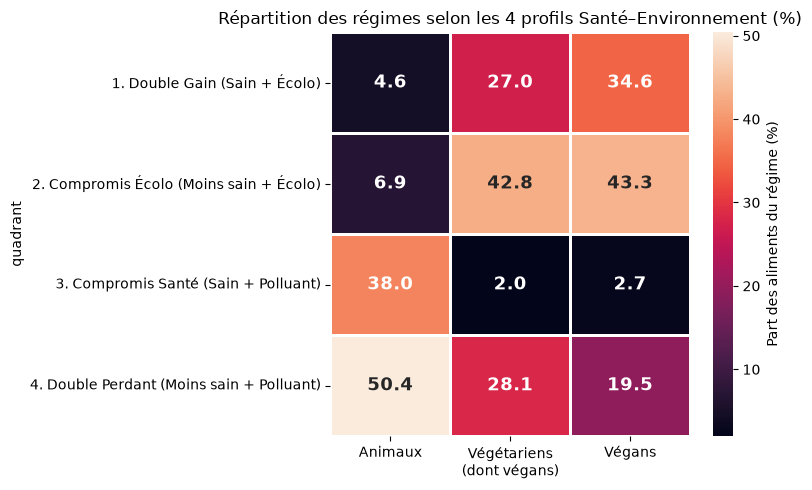

In [16]:
## Visualisation graphique: découpage de l'espace en 4 cadrans
seuil_ef = df1["score_unique_ef"].median()
bon_nutri = (df1["SAIN"] >= 5.0) & (df1["LIM"] < 7.5)
faible_ef = df1["score_unique_ef"] <= seuil_ef

conditions = [
    bon_nutri & faible_ef,
    ~bon_nutri & faible_ef,
    bon_nutri & ~faible_ef,
    ~bon_nutri & ~faible_ef]

# Puis on classe chaque aliment dans l'un de ces quadrans
labels = [
    "1. Double Gain (Sain + Écolo)",
    "2. Compromis Écolo (Moins sain + Écolo)",
    "3. Compromis Santé (Sain + Polluant)",
    "4. Double Perdant (Moins sain + Polluant)"]
df1["quadrant"] = np.select(conditions, labels, default="Autre")

ensembles = {
    "Animaux": df1[df1["est_animal"]],
    "Végétariens\n(dont végans)": df1[df1["est_vegetarien"]],
    "Végans": df1[df1["est_vegan"]]}

tab_quadrants = pd.DataFrame({
    nom: (sub["quadrant"].value_counts(normalize=True) * 100).round(1)
    for nom, sub in ensembles.items()
}).reindex(labels)


fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    tab_quadrants,annot=True,fmt=".1f",
    cbar_kws={"label": "Part des aliments du régime (%)"},
    linewidths=2,linecolor="white", annot_kws={"size": 13, "weight": "bold"})

ax.set_title("Répartition des régimes selon les 4 profils Santé–Environnement (%)")
    
plt.tight_layout()
plt.show()

## Interprétation:

La matrice montre que les produits animaux se concentrent majoritairement dans la zone des Doubles Perdants ou de Compromis Santé, là où le Double Gain reste marginal pour ce type d'aliments. À l'inverse, le passage aux produits végétariens et végans multiplie par plus de six la part d'aliments atteignant le Double Gain (respectivement 27 et 34,6%). 

Toutefois, ici l'analyse manque de finesse car on ne s'est pas restreint aux alternatives à la viande (les produits végans incluant par exemple l'ensemble des fruits et légumes qui sont plus sains mais qui n'offrent pas les mêmes apports nutritifs que la viande / poisson). Ainsi dans un deuxième temps de l'analyse, on restreindra nos observations aux ingrédients "protéinés". 

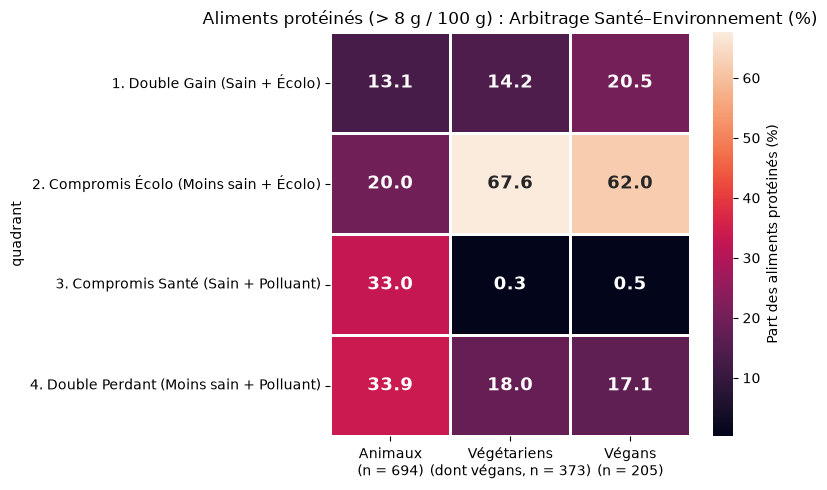

In [19]:
col_prot = "Protéines, N x facteur de Jones (g 100 g)"

# 1. Filtrer uniquement les aliments riches en protéines (>= 8 g / 100 g) et qui ne sont pas des épices ou condiments
df_prot = df1[
    (df1[col_prot] >= 8.0)
    & (~df1["groupe_aliment"].isin(["boissons", "aliments infantiles"]))
    & (~df1["sous_groupe_aliment"].isin(["sels", "herbes", "épices", "ingrédients divers", "algues"]))
    & (df1["score_unique_ef"] > 0)].copy()

# Ramener l'impact environnemental à 100 g de protéines
df_prot["ef_par_100g_prot"] = (df_prot["score_unique_ef"] / df_prot[col_prot]) * 100

# 2. Découpage en 4 quadrants à apport protéique équivalent
seuil_ef_prot = df_prot["ef_par_100g_prot"].median()
bon_nutri = (df_prot["SAIN"] >= 5.0) & (df_prot["LIM"] < 7.5)
faible_ef_prot = df_prot["ef_par_100g_prot"] <= seuil_ef_prot

conditions = [
    bon_nutri & faible_ef_prot,
    ~bon_nutri & faible_ef_prot,
    bon_nutri & ~faible_ef_prot,
    ~bon_nutri & ~faible_ef_prot]

labels_q = [
    "1. Double Gain (Sain + Écolo)",
    "2. Compromis Écolo (Moins sain + Écolo)",
    "3. Compromis Santé (Sain + Polluant)",
    "4. Double Perdant (Moins sain + Polluant)"]
df_prot["quadrant"] = np.select(conditions, labels_q, default="Autre")

ensembles = {
    f"Animaux\n(n = {df_prot['est_animal'].sum()})": df_prot[
        df_prot["est_animal"]
    ],
    f"Végétariens\n(dont végans, n = {df_prot['est_vegetarien'].sum()})": (
        df_prot[df_prot["est_vegetarien"]]
    ),
    f"Végans\n(n = {df_prot['est_vegan'].sum()})": df_prot[
        df_prot["est_vegan"]]}

tab_q_prot = pd.DataFrame({
    nom: (sub["quadrant"].value_counts(normalize=True) * 100).round(1)
    for nom, sub in ensembles.items()}).reindex(labels_q)

# Heatmap des produits protéinés
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(tab_q_prot,annot=True,
    fmt=".1f",cbar_kws={"label": "Part des aliments protéinés (%)"},
    linewidths=2,linecolor="white",annot_kws={"size": 13, "weight": "bold"})

ax.set_title("Aliments protéinés (> 8 g / 100 g) : Arbitrage Santé–Environnement (%)")
plt.tight_layout()
plt.show()


## Interprétation:

Lorsqu'on restreint l'analyse aux aliments sources de protéines (>8g/100g) et qu'on ramène l'impact environnemental à 100g de protéines, les protéines véganes restent en tête sur le Double Gain (20,5%) contre 13,1% pour les protéines animales, mais un arbitrage majeur apparaît chez les protéines végétales. En effet, une grande partie des produits végétaux protéinés (comme le pain non-complet, les similis carnés salés, ou fromages) ont une empreinte carbone faible par gramme de protéines mais sont pénalisés sur le plan nutritionnel par le sel, les sucres ou les graisses saturées qu'ils contiennent. 

Ainsi, comme le soulignait Libération, « végétal » ne rime pas systématiquement avec « irréprochable" sur le plan nutritionnel. Lorsque l'on restreint l'analyse aux aliments riches en protéines (>= 8 g / 100 g), une part importante des produits végétaux ou substituts se retrouve pénalisée sur le plan nutritionnel malgré un impact environnemental plus favorable. 

In [ ]:
# Sélection des aliments protéinés en Double Gain: ie ici on ne garde que ceux les aliments qui sont à la fois bons nutritionnellement (bon_nutri) 
# et peu impactants environnementalement parlant (faible_ef_prot en dessous de la médiane) -> cela correspond à notre cadran double-gain. Et on regarde (en comptant)
# quelle est la famille qui domine ce cadran.

vainqueurs_prot = df_prot[bon_nutri & faible_ef_prot].copy()
print("Répartition des produits protéinés en Double Gain par famille:")
print(vainqueurs_prot["sous_groupe_aliment"].value_counts().head(8))

# Quel ingrédient a le meilleur rang en moyenne sur sur les indicateurs bruts (impact minimal, LIM minimal, SAIN maximal) ?
vainqueurs_prot = df_prot[bon_nutri & faible_ef_prot].copy()
rang_ef = vainqueurs_prot["ef_par_100g_prot"].rank(ascending=True)
rang_sain = vainqueurs_prot["SAIN"].rank(ascending=False)
rang_lim = vainqueurs_prot["LIM"].rank(ascending=True)

vainqueurs_prot["rang_moyen"] = (rang_ef + rang_sain + rang_lim) / 3
top15 = vainqueurs_prot.sort_values("rang_moyen", ascending=True)

display(top15[["nom_produit","sous_groupe_aliment","type_base",col_prot,"ef_par_100g_prot","SAIN","LIM","rang_moyen"]].head(15).round(1))

Répartition des produits protéinés en Double Gain par famille:
sous_groupe_aliment
viandes crues             33
viandes cuites            24
légumineuses              22
poissons crus             22
pâtes, riz et céréales     8
œufs                       7
substituts de viande       6
poissons cuits             4
Name: count, dtype: int64


,nom_produit,sous_groupe_aliment,type_base,"Protéines, N x facteur de Jones (g 100 g)",ef_par_100g_prot,SAIN,LIM,rang_moyen
948,"Haricot blanc, sec",légumineuses,vegan,23.40,0.35,13.30,0.50,8.67
953,"Haricot flageolet, vert, sec",légumineuses,vegan,19.10,0.53,11.53,0.61,15.00
957,"Haricot rouge, cuit",légumineuses,vegan,9.63,0.69,14.87,0.71,15.00
955,"Haricot mungo, sec",légumineuses,vegan,25.20,0.39,10.92,0.57,15.67
963,"Lentille verte, cuite",légumineuses,vegan,10.10,0.88,11.72,0.34,18.00
952,"Haricot flageolet, vert, cuit",légumineuses,vegan,8.50,0.79,14.91,0.90,18.33
961,"Lentille corail, cuite",légumineuses,vegan,10.60,0.84,11.20,0.36,19.67
959,"Lentille blonde, cuite",légumineuses,vegan,9.70,0.91,10.21,0.52,25.33
941,"Fève, cuite",légumineuses,vegan,8.06,0.83,9.83,0.61,26.67
967,"Lupin, graine crue",légumineuses,vegan,36.20,0.36,10.68,1.92,28.00


## Interprétation: 

Pour hiérarchiser les aliments qui se situent dans le cadran Double Gain nous utilisons un rang moyen (nous passons par le rang plutôt que par la moyenne afin de ne pas mélanger des unités hétérogènes). Ici, chaque aliment est classé selon trois critères : l'impact environnemental par 100 g de protéines (ef_par_100g_prot, du plus faible au plus élevé), le score SAIN (du plus élevé au plus faible) et le score LIM (du plus faible au plus élevé). Le rang_moyen correspond alors à la moyenne de ces trois rangs: plus il est faible et plus l'aliment est bien positionné globalement sur l'ensemble des trois dimensions. Dans ce Top15, les légumineuses (haricots, lentilles, lupin, pois cassé) dominent l'intégralité du classement: leur profil est donc idéal, car à la fois favorable sur le plan nutritionnel et sur l'empreinte environnementale à apport protéique comparable.